# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  :Dhimas Baga Yulistyana
- NIM   :241011400040
- Kelas : Reg B / ~~Reg C~~ *(coret salah satu)*

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [54]:
# import Library
%pip install pandas numpy matplotlib scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 40  # dua digit terakhir NIM: 40

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [55]:
def train_test_split(X, y, test_size=0.25, random_state=None):
    """Split arrays using a seeded shuffle, without scikit-learn."""
    X = np.asarray(X)
    y = np.asarray(y)
    if len(X) != len(y):
        raise ValueError("X and y must contain the same number of samples")
    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    rng = np.random.RandomState(random_state)
    indices = rng.permutation(len(X))
    n_test = int(np.ceil(len(X) * test_size))
    test_indices = indices[:n_test]
    train_indices = indices[n_test:]
    return X[train_indices], X[test_indices], y[train_indices], y[test_indices]

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris: 40
Shape X: (40, 1) | Shape y: (40,)


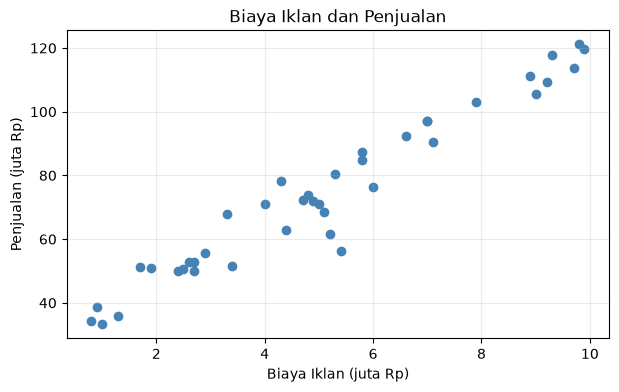

In [56]:
# Jawaban A1
ads_data = pd.read_csv("Ads_Data.csv")
display(ads_data.head())
print("Jumlah baris:", len(ads_data))

X_ads = ads_data[["BiayaIklan"]].to_numpy(dtype=float)
y_ads = ads_data["Penjualan"].to_numpy(dtype=float)
print("Shape X:", X_ads.shape, "| Shape y:", y_ads.shape)

plt.figure(figsize=(7, 4))
plt.scatter(X_ads[:, 0], y_ads, color="steelblue")
plt.title("Biaya Iklan dan Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.25)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [57]:
# Jawaban A2
X_train_ads, X_test_ads, y_train_ads, y_test_ads = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train_ads.shape)
print("X_test :", X_test_ads.shape)
print("y_train:", y_train_ads.shape)
print("y_test :", y_test_ads.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [58]:
# Jawaban A3
class LinearRegression:
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.pinv(X_b.T @ X_b) @ X_b.T @ y
        self.intercept_ = float(beta[0])
        self.coef_ = beta[1:]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_


linear_model = LinearRegression().fit(X_train_ads, y_train_ads)
print(f"Intercept (b): {linear_model.intercept_:.4f}")
print(f"Koefisien (m): {linear_model.coef_[0]:.4f}")
print(f"Persamaan: y_hat = {linear_model.intercept_:.4f} + {linear_model.coef_[0]:.4f}X")

Intercept (b): 28.6313
Koefisien (m): 9.1684
Persamaan: y_hat = 28.6313 + 9.1684X


**Jawaban A3 (interpretasi):** Koefisien $m$ menyatakan perubahan prediksi penjualan untuk setiap kenaikan biaya iklan sebesar 1 juta rupiah. Berdasarkan koefisien yang dicetak pada sel A3, setiap tambahan Rp1 juta biaya iklan diperkirakan mengubah penjualan sebesar nilai koefisien tersebut juta rupiah. Ini adalah hubungan linear pada data dan tidak membuktikan bahwa iklan sendirian menyebabkan perubahan penjualan.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [59]:
# Jawaban A4
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=float).reshape(-1)
    errors = y_true - y_pred
    mae = np.mean(np.abs(errors))
    mse = np.mean(errors ** 2)
    rmse = np.sqrt(mse)
    denominator = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - np.sum(errors ** 2) / denominator if denominator != 0 else np.nan
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

train_ads_metrics = regression_metrics(y_train_ads, linear_model.predict(X_train_ads))
test_ads_metrics = regression_metrics(y_test_ads, linear_model.predict(X_test_ads))
metrics_ads = pd.DataFrame(
    [train_ads_metrics, test_ads_metrics], index=["Training", "Testing"]
)
display(metrics_ads.round(4))
print(
    f"RMSE testing = {test_ads_metrics['RMSE']:.3f} juta Rp: "
    "besar galat tipikal dalam satuan penjualan."
)
print(
    f"R2 testing = {test_ads_metrics['R2']:.3f}: "
    "proporsi variasi penjualan pada data testing yang dijelaskan model."
)

,MAE,MSE,RMSE,R2
Training,3.4789,19.1359,4.3745,0.9710
Testing,8.2791,106.1912,10.3049,0.7008


RMSE testing = 10.305 juta Rp: besar galat tipikal dalam satuan penjualan.
R2 testing = 0.701: proporsi variasi penjualan pada data testing yang dijelaskan model.


**Jawaban A4 (analisis):** RMSE menyatakan besar kesalahan prediksi tipikal dalam satuan juta rupiah, sehingga lebih mudah dibandingkan langsung dengan skala penjualan. $R^2$ menunjukkan seberapa besar variasi penjualan yang dapat dijelaskan oleh hubungan linear; nilai mendekati 1 lebih baik, sedangkan nilai negatif berarti model lebih buruk daripada memakai rata-rata data testing. Bandingkan baris training dan testing pada tabel: jika galat testing jauh lebih tinggi atau $R^2$ turun tajam, kemampuan generalisasi model terbatas. Kesimpulan akhir perlu mempertimbangkan nilai aktual yang tercetak di atas.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

In [60]:
# Jawaban A5
class LinearRegressionGD:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])
        self.loss_history_ = []
        with np.errstate(over="ignore", invalid="ignore"):
            for iteration in range(self.n_iterations):
                errors = X_b @ beta - y
                beta -= self.learning_rate * (2 / len(y)) * (X_b.T @ errors)
                if iteration % 10 == 0 or iteration == self.n_iterations - 1:
                    residuals = X_b @ beta - y
                    self.loss_history_.append(np.mean(residuals ** 2))
        self.intercept_ = float(beta[0])
        self.coef_ = beta[1:]
        return self

    def predict(self, X):
        return self.intercept_ + np.asarray(X, dtype=float) @ self.coef_


learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
plt.figure(figsize=(8, 5))
for rate in learning_rates:
    model = LinearRegressionGD(learning_rate=rate, n_iterations=5000).fit(
        X_train_ads, y_train_ads
    )
    gd_models[rate] = model
    finite_loss = np.asarray(model.loss_history_)
    finite_loss = finite_loss[np.isfinite(finite_loss) & (finite_loss > 0)]
    print(
        f"lr={rate}: intercept={model.intercept_:.6g}, "
        f"koefisien={model.coef_[0]:.6g}, "
        f"loss akhir={model.loss_history_[-1]:.6g}"
    )
    if len(finite_loss):
        plt.plot(np.arange(len(finite_loss)) * 10, finite_loss, label=f"lr={rate}")
    else:
        print(f"lr={rate}: loss tidak finite; model divergen pada skala fitur ini.")

plt.yscale("log")
plt.title("Gradient Descent: MSE terhadap Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("MSE (skala log)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()
print(
    f"Normal equation: intercept={linear_model.intercept_:.6g}, "
    f"koefisien={linear_model.coef_[0]:.6g}"
)

lr=0.001: intercept=25.3076, koefisien=9.66438, loss akhir=21.4871
lr=0.02: intercept=28.6313, koefisien=9.16843, loss akhir=19.1359
lr=0.1: intercept=nan, koefisien=nan, loss akhir=nan


c:\Users\bagad\AppData\Local\Programs\Python\Python312\Lib\site-packages\matplotlib\ticker.py:2587: RuntimeWarning: overflow encountered in power
  ticklocs = b ** np.array(decades)


OverflowError: cannot convert float infinity to integer

<Figure size 800x500 with 1 Axes>

Normal equation: intercept=28.6313, koefisien=9.16843


**Jawaban A5 (analisis):** Learning rate yang terlalu kecil membuat penurunan loss per iterasi lambat, sedangkan nilai yang sesuai menurunkan loss secara stabil dan menghasilkan parameter mendekati normal equation. Learning rate terlalu besar dapat membuat langkah pembaruan melewati titik minimum berulang kali sehingga loss membesar, menjadi `inf`/`nan`, atau koefisien tidak finite; itulah divergensi, bukan sekadar akurasi yang rendah. Gunakan kurva dan nilai akhir di atas untuk mengidentifikasi perilaku masing-masing dari tiga learning rate. Perbandingan harus dilihat pada skala fitur yang digunakan karena besar fitur memengaruhi ukuran langkah yang stabil.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

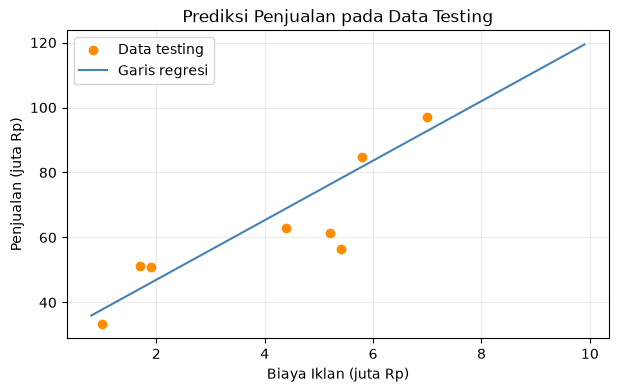

,BiayaIklan_juta_Rp,PrediksiPenjualan_juta_Rp
0,4.5,69.889207
1,7.0,92.810272
2,12.0,138.652402


In [61]:
# Jawaban A6
x_line = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)
plt.figure(figsize=(7, 4))
plt.scatter(X_test_ads[:, 0], y_test_ads, color="darkorange", label="Data testing")
plt.plot(x_line[:, 0], linear_model.predict(x_line), color="steelblue", label="Garis regresi")
plt.title("Prediksi Penjualan pada Data Testing")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

iklan_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = linear_model.predict(iklan_baru)
display(pd.DataFrame({
    "BiayaIklan_juta_Rp": iklan_baru[:, 0],
    "PrediksiPenjualan_juta_Rp": prediksi_penjualan
}))

**Jawaban A6 (analisis):** Prediksi pada biaya iklan 12 juta merupakan ekstrapolasi karena nilainya berada di luar rentang biaya iklan pada dataset. Hasil itu perlu dianggap lebih tidak pasti: model mengasumsikan hubungan linear tetap berlaku di luar pengamatan, padahal pola pasar dapat berubah dan tidak ada data yang menguji asumsi tersebut. Prediksi 4.5 dan 7 juta lebih dekat dengan rentang yang diamati sehingga lebih didukung data, meskipun tetap merupakan estimasi.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah kelas:
Spam
Bukan Spam    35
Spam          25
Name: count, dtype: int64


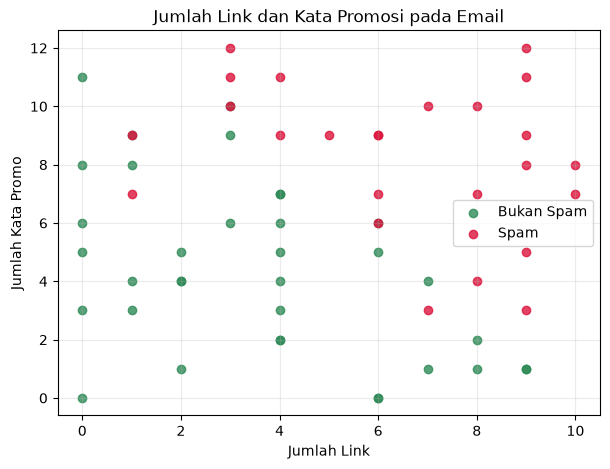

In [62]:
# Jawaban B1
email_data = pd.read_csv("Email_Data.csv")
display(email_data.head())
print("Jumlah kelas:")
print(email_data["Spam"].value_counts().rename(index={0: "Bukan Spam", 1: "Spam"}))

X_email = email_data[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_email = email_data["Spam"].to_numpy(dtype=int)

plt.figure(figsize=(7, 5))
for label, color, name in [(0, "seagreen", "Bukan Spam"), (1, "crimson", "Spam")]:
    mask = y_email == label
    plt.scatter(X_email[mask, 0], X_email[mask, 1], color=color, label=name, alpha=0.8)
plt.title("Jumlah Link dan Kata Promosi pada Email")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b): -11.2618
Koefisien (m1, m2): [1.0437 0.8897]
P(Spam) = sigmoid(-11.2618 + (1.0437)JumlahLink + (0.8897)KataPromo)


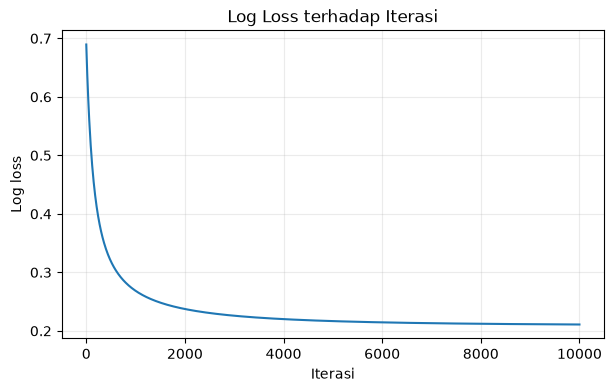

Log loss awal=0.6895; akhir=0.2109


In [63]:
# Jawaban B2
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

class LogisticRegression:
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    @staticmethod
    def _sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])
        self.loss_history_ = []
        for iteration in range(self.n_iterations):
            probabilities = self._sigmoid(X_b @ beta)
            beta -= self.learning_rate * (X_b.T @ (probabilities - y)) / len(y)
            if iteration % 10 == 0 or iteration == self.n_iterations - 1:
                probabilities = np.clip(self._sigmoid(X_b @ beta), 1e-12, 1 - 1e-12)
                loss = -np.mean(y * np.log(probabilities) + (1 - y) * np.log(1 - probabilities))
                self.loss_history_.append(loss)
        self.intercept_ = float(beta[0])
        self.coef_ = beta[1:]
        self.coefficients_ = self.coef_
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        return self._sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


logistic_model = LogisticRegression(learning_rate=0.1, n_iterations=10000).fit(
    X_train_email, y_train_email
)
print(f"Intercept (b): {logistic_model.intercept_:.4f}")
print("Koefisien (m1, m2):", np.round(logistic_model.coef_, 4))
print(
    "P(Spam) = sigmoid(" + f"{logistic_model.intercept_:.4f} "
    f"+ ({logistic_model.coef_[0]:.4f})JumlahLink "
    f"+ ({logistic_model.coef_[1]:.4f})KataPromo)"
)

plt.figure(figsize=(7, 4))
plt.plot(np.arange(len(logistic_model.loss_history_)) * 10, logistic_model.loss_history_)
plt.title("Log Loss terhadap Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.grid(alpha=0.25)
plt.show()
print(f"Log loss awal={logistic_model.loss_history_[0]:.4f}; akhir={logistic_model.loss_history_[-1]:.4f}")

**Jawaban B2 (analisis):** Loss awal dan akhir serta grafik menunjukkan apakah proses belajar berhasil: loss yang turun lalu mendatar menandakan optimisasi mulai stabil. Koefisien positif menaikkan probabilitas spam ketika fitur terkait bertambah, sedangkan koefisien negatif menurunkannya. Interpretasi ini berlaku dengan fitur lain dianggap tetap; model tetap sederhana dan hasilnya bergantung pada sampel training.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [64]:
# Jawaban B3
def confusion_matrix_numpy(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int).reshape(-1)
    y_pred = np.asarray(y_pred, dtype=int).reshape(-1)
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    return np.array([[tn, fp], [fn, tp]])


def classification_metrics(y_true, y_pred):
    matrix = confusion_matrix_numpy(y_true, y_pred)
    tn, fp, fn, tp = matrix.ravel()
    accuracy = (tp + tn) / matrix.sum() if matrix.sum() else 0.0
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {"Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1": f1}, matrix


y_pred_email = logistic_model.predict(X_test_email)
email_metrics, email_confusion = classification_metrics(y_test_email, y_pred_email)
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(email_confusion)
display(pd.DataFrame([email_metrics], index=["Testing"]).round(4))
tn, fp, fn, tp = email_confusion.ravel()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

Confusion matrix [[TN, FP], [FN, TP]]:
[[4 1]
 [1 9]]


,Accuracy,Precision,Recall,F1
Testing,0.8667,0.9,0.9,0.9


TN=4, FP=1, FN=1, TP=9


**Jawaban B3 (analisis):** FP adalah email bukan spam yang keliru diberi label spam; email sah dapat masuk folder spam atau terlewat pengguna. FN adalah email spam yang keliru dianggap bukan spam sehingga masuk inbox. Untuk filter yang ketat, saya menganggap FP lebih merugikan karena pesan penting berisiko tidak terbaca, tetapi dampak relatifnya tergantung konteks dan ketersediaan folder pemulihan. Gunakan nilai FP dan FN pada confusion matrix di atas untuk menilai trade-off model ini.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: -11.2618 + (1.0437)x1 + (0.8897)x2 = 0


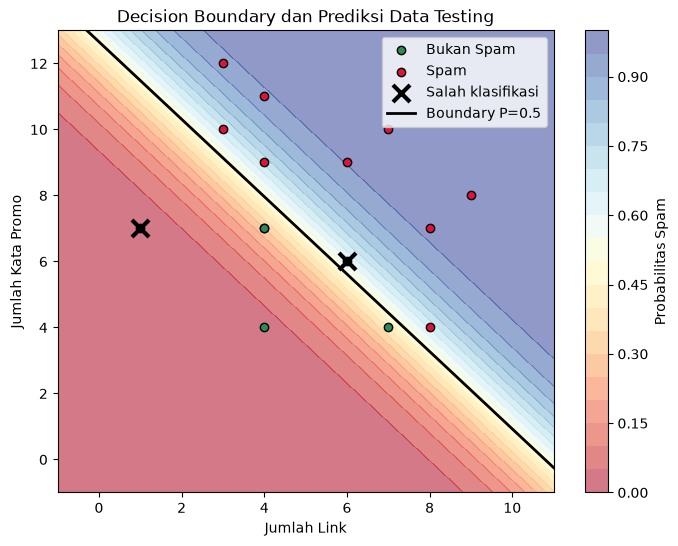

,JumlahLink,KataPromo,Aktual,Prediksi
0,1,7,1,0
1,6,6,0,1


In [65]:
# Jawaban B4
b = logistic_model.intercept_
m1, m2 = logistic_model.coef_
print(f"Decision boundary: {b:.4f} + ({m1:.4f})x1 + ({m2:.4f})x2 = 0")

x1_values = np.linspace(X_email[:, 0].min() - 1, X_email[:, 0].max() + 1, 180)
x2_values = np.linspace(X_email[:, 1].min() - 1, X_email[:, 1].max() + 1, 180)
grid_x1, grid_x2 = np.meshgrid(x1_values, x2_values)
grid_points = np.c_[grid_x1.ravel(), grid_x2.ravel()]
probability_grid = logistic_model.predict_proba(grid_points).reshape(grid_x1.shape)

plt.figure(figsize=(8, 6))
plt.contourf(grid_x1, grid_x2, probability_grid, levels=20, cmap="RdYlBu", alpha=0.55)
plt.colorbar(label="Probabilitas Spam")
for label, color, name in [(0, "seagreen", "Bukan Spam"), (1, "crimson", "Spam")]:
    mask = y_test_email == label
    plt.scatter(X_test_email[mask, 0], X_test_email[mask, 1], color=color, edgecolor="black", label=name)
misclassified = y_pred_email != y_test_email
plt.scatter(
    X_test_email[misclassified, 0], X_test_email[misclassified, 1],
    marker="x", s=150, linewidths=3, color="black", label="Salah klasifikasi"
)
if abs(m2) > 1e-12:
    boundary_x1 = np.linspace(x1_values.min(), x1_values.max(), 200)
    boundary_x2 = -(b + m1 * boundary_x1) / m2
    visible = (boundary_x2 >= x2_values.min()) & (boundary_x2 <= x2_values.max())
    plt.plot(boundary_x1[visible], boundary_x2[visible], color="black", linewidth=2, label="Boundary P=0.5")
plt.title("Decision Boundary dan Prediksi Data Testing")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.show()

if np.any(misclassified):
    display(pd.DataFrame({
        "JumlahLink": X_test_email[misclassified, 0].astype(int),
        "KataPromo": X_test_email[misclassified, 1].astype(int),
        "Aktual": y_test_email[misclassified],
        "Prediksi": y_pred_email[misclassified]
    }))
else:
    print("Tidak ada data testing yang salah diklasifikasikan pada threshold 0.5.")

**Jawaban B4 (analisis):**

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [66]:
# Jawaban B5
threshold_rows = []
probabilities_test = logistic_model.predict_proba(X_test_email)
for threshold in [0.3, 0.5, 0.7]:
    predictions = (probabilities_test >= threshold).astype(int)
    scores, matrix = classification_metrics(y_test_email, predictions)
    tn, fp, fn, tp = matrix.ravel()
    threshold_rows.append({
        "Threshold": threshold,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
        "ConfusionMatrix": str(matrix.tolist()),
        "Precision": scores["Precision"],
        "Recall": scores["Recall"]
    })
threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(4))

# Threshold pilihan untuk B6: lebih konservatif dalam menandai email sebagai spam.
spam_threshold = 0.7
print(f"Threshold pilihan untuk prediksi email baru: {spam_threshold}")

,Threshold,TN,FP,FN,TP,ConfusionMatrix,Precision,Recall
0,0.3,3,2,1,9,"[[3, 2], [1, 9]]",0.8182,0.9
1,0.5,4,1,1,9,"[[4, 1], [1, 9]]",0.9000,0.9
2,0.7,5,0,3,7,"[[5, 0], [3, 7]]",1.0000,0.7


Threshold pilihan untuk prediksi email baru: 0.7


**Jawaban B5 (analisis):** Menurunkan threshold membuat lebih banyak email diprediksi spam; biasanya recall naik karena lebih banyak spam tertangkap, tetapi FP juga dapat bertambah dan precision dapat turun. Menaikkan threshold membuat model lebih selektif, yang biasanya menekan FP tetapi berisiko menaikkan FN. Saya memilih threshold 0.7 untuk mengurangi kemungkinan email penting masuk folder spam; pilihan ini menerima risiko sebagian spam lolos, sehingga sebaiknya disesuaikan dengan trade-off pada tabel hasil.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [67]:
# Jawaban B6
new_emails = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})
new_email_features = new_emails[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
new_email_probabilities = logistic_model.predict_proba(new_email_features)
new_emails["ProbabilitasSpam"] = new_email_probabilities
new_emails["Prediksi"] = np.where(
    new_email_probabilities >= spam_threshold, "Spam", "Bukan Spam"
)
display(new_emails.round(4))
print(f"Klasifikasi menggunakan threshold {spam_threshold:.1f}.")

,Email,JumlahLink,KataPromo,ProbabilitasSpam,Prediksi
0,E1,1,2,0.0002,Bukan Spam
1,E2,5,6,0.3307,Bukan Spam
2,E3,9,10,0.9991,Spam
3,E4,2,11,0.6485,Bukan Spam


Klasifikasi menggunakan threshold 0.7.


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression disebut klasifikasi karena tujuan akhirnya memilih kelas, misalnya spam atau bukan spam, bukan memprediksi nilai kontinu tanpa batas. Model menghitung skor linear dari fitur lalu memasukkannya ke fungsi sigmoid. Sigmoid mengubah skor menjadi probabilitas antara 0 dan 1. Probabilitas itu kemudian dibandingkan dengan threshold untuk menentukan kelas.

**Jawaban C2:** Normal equation menghitung koefisien secara langsung melalui operasi matriks, tanpa iterasi dan tanpa memilih learning rate. Gradient descent memperbarui koefisien berulang kali mengikuti arah yang menurunkan loss. Gradient descent lebih sesuai ketika jumlah fitur atau data besar sehingga operasi matriks langsung mahal, atau saat bentuk solusi langsung tidak praktis. Namun, learning rate dan skala fitur perlu dipilih dengan hati-hati.

**Jawaban C3:** Data training dipakai untuk menemukan parameter, sehingga evaluasi pada data yang sama cenderung memberi gambaran terlalu optimistis. Data testing memberikan perkiraan performa pada data baru yang tidak dipakai saat training. Overfitting terjadi saat model terlalu menyesuaikan diri pada pola atau noise training sehingga performanya menurun pada data baru. Karena itu, metrik testing lebih relevan untuk menilai generalisasi.

**Jawaban C4:** Linear Regression menghasilkan prediksi nilai kontinu dan MSE mengukur kuadrat jarak prediksi dari nilai target. Logistic Regression menghasilkan probabilitas kelas, sehingga log loss menilai kualitas probabilitas dan memberi penalti besar pada prediksi yang sangat yakin tetapi salah. Log loss juga sesuai dengan pemodelan target biner sebagai distribusi Bernoulli. Keduanya dipilih sesuai jenis keluaran model.

**Jawaban C5:** Random state yang berbeda menghasilkan anggota data training dan testing yang berbeda, sehingga parameter dan metrik dapat ikut berubah. Bahkan dengan split sama, implementasi, inisialisasi, learning rate, jumlah iterasi, dan preprocessing dapat memengaruhi hasil. Dataset kecil membuat perubahan beberapa sampel lebih terasa. Karena itu, perbandingan harus memakai prosedur dan konfigurasi yang sama.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [68]:
# Jawaban Bonus
try:
    sklearn_linear_models = __import__(
        "sklearn.linear_model", fromlist=["LinearRegression", "LogisticRegression"]
    )
    SklearnLinearRegression = sklearn_linear_models.LinearRegression
    SklearnLogisticRegression = sklearn_linear_models.LogisticRegression

    sklearn_linear = SklearnLinearRegression().fit(X_train_ads, y_train_ads)
    sklearn_train_pred_ads = sklearn_linear.predict(X_train_ads)
    sklearn_test_pred_ads = sklearn_linear.predict(X_test_ads)
    print("Linear Regression scikit-learn")
    print("Intercept:", sklearn_linear.intercept_, "Koefisien:", sklearn_linear.coef_)
    display(pd.DataFrame([
        {"Split": "Training", **regression_metrics(y_train_ads, sklearn_train_pred_ads)},
        {"Split": "Testing", **regression_metrics(y_test_ads, sklearn_test_pred_ads)}
    ]).set_index("Split").round(4))
    print("Selisih koefisien linear (implementasi sendiri - sklearn):",
          linear_model.coef_ - sklearn_linear.coef_)

    sklearn_logistic = SklearnLogisticRegression(max_iter=10000).fit(
        X_train_email, y_train_email
    )
    sklearn_probabilities = sklearn_logistic.predict_proba(X_test_email)[:, 1]
    sklearn_predictions = (sklearn_probabilities >= 0.5).astype(int)
    sklearn_metrics, sklearn_confusion = classification_metrics(y_test_email, sklearn_predictions)
    print("\nLogistic Regression scikit-learn (threshold 0.5)")
    print("Intercept:", sklearn_logistic.intercept_[0], "Koefisien:", sklearn_logistic.coef_[0])
    print("Confusion matrix [[TN, FP], [FN, TP]]:")
    print(sklearn_confusion)
    display(pd.DataFrame([sklearn_metrics], index=["Testing"]).round(4))
    print("Parameter logistic model sendiri:", logistic_model.intercept_, logistic_model.coef_)
    print("Parameter logistic sklearn:", sklearn_logistic.intercept_[0], sklearn_logistic.coef_[0])
except ImportError:
    print("Bonus memerlukan scikit-learn. Instal paket lalu jalankan ulang sel ini.")

Linear Regression scikit-learn
Intercept: 28.631289418719803 Koefisien: [9.16842602]


,MAE,MSE,RMSE,R2
Split,,,,
Training,3.4789,19.1359,4.3745,0.9710
Testing,8.2791,106.1912,10.3049,0.7008


Selisih koefisien linear (implementasi sendiri - sklearn): [-3.55271368e-14]

Logistic Regression scikit-learn (threshold 0.5)
Intercept: -10.445187047845385 Koefisien: [0.95892659 0.82320467]
Confusion matrix [[TN, FP], [FN, TP]]:
[[4 1]
 [1 9]]


,Accuracy,Precision,Recall,F1
Testing,0.8667,0.9,0.9,0.9


Parameter logistic model sendiri: -11.261808179315294 [1.04373016 0.88970866]
Parameter logistic sklearn: -10.445187047845385 [0.95892659 0.82320467]


**Jawaban Bonus (analisis):** Koefisien Linear Regression normal equation dan scikit-learn seharusnya sangat dekat karena keduanya meminimalkan jumlah kuadrat galat tanpa regularisasi. Hasil Logistic Regression dapat berbeda karena implementasi sendiri tidak memakai regularisasi, sedangkan `sklearn` secara default memakai penalti L2 (`C=1.0`); selain itu metode optimisasi dan kriteria berhenti juga berbeda. Bandingkan parameter dan metrik yang benar-benar tercetak di atas, terutama karena akurasi pada data testing kecil dapat berubah akibat satu prediksi saja.